<a href="https://colab.research.google.com/github/shohidulremon/bank-loan-default-prediction/blob/main/Bank_Loan_Default_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# STEP 1: IMPORT LIBRARIES & LOAD DATASET
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve
)
from sklearn.inspection import permutation_importance

# Load dataset
df_raw = pd.read_csv('/content/banking_loan_defaults.csv')
print(f"Raw Dataset Shape: {df_raw.shape}")
df_raw.head()

Raw Dataset Shape: (10050, 22)


,loan_id,age,gender,annual_income_bdt,employment_years,loan_amount_bdt,loan_term_months,interest_rate_pct,loan_purpose,collateral_type,...,credit_score,num_late_payments_12m,monthly_payment_bdt,monthly_income_used_pct,num_inquiries_6m,payment_frequency,days_to_default_resolution,delinquency_status,recovery_amount_bdt,default
0,LN1008776,49,Male,59837.0,0.773261,176230.0,12,7.43,Home,Vehicle,...,NaN,0,189328,150.0,0,Monthly,NaN,NaN,NaN,0
1,LN1002199,32,Female,NaN,8.424624,266650.0,36,8.22,Auto,NaN,...,734.0,1,96185,150.0,1,Monthly,246.0,90+days,48856.0,1
2,LN1009596,61,Female,161733.0,1.540981,85152.0,48,8.35,Home,NaN,...,617.0,2,23064,150.0,0,Monthly,35.0,30days,36140.0,1
3,LN1008490,45,Male,NaN,5.586240,41856.0,36,11.92,Auto,NaN,...,NaN,2,15614,150.0,0,Monthly,330.0,30days,26635.0,1
4,LN1003314,55,Male,121258.0,4.353345,229690.0,48,7.22,Home,NaN,...,647.0,1,61567,150.0,2,Monthly,NaN,NaN,NaN,0


In [2]:
# ==============================================================================
# STEP 2: DATA CLEANING & DATA LEAKAGE REMOVAL
# ==============================================================================
# 1. Remove duplicate records based on unique loan_id (50 exact duplicate rows)
df = df_raw.drop_duplicates(subset=['loan_id']).copy()

# 2. Drop ID column and post-default target leakage columns
# (days_to_default_resolution, delinquency_status, and recovery_amount_bdt are only recorded AFTER a default occurs)
leakage_and_id_cols = [
    'loan_id',
    'days_to_default_resolution',
    'delinquency_status',
    'recovery_amount_bdt'
]
df = df.drop(columns=leakage_and_id_cols)

# 3. Replace sentinel outlier codes with NaN so the pipeline imputer handles them properly
df['age'] = df['age'].replace(999, np.nan)
df['credit_score'] = df['credit_score'].replace(-1.0, np.nan)

# 4. Standardize inconsistent text casing in categorical features
df['gender'] = df['gender'].str.strip().str.title()
df['loan_purpose'] = df['loan_purpose'].str.strip().str.title()

print(f"Cleaned Dataset Shape: {df.shape}")
print(f"Target Distribution (default):\n{df['default'].value_counts(normalize=True).round(4)}")

Cleaned Dataset Shape: (10000, 18)
Target Distribution (default):
default
0    0.7056
1    0.2944
Name: proportion, dtype: float64


In [3]:
# ==============================================================================
# STEP 3: BUILD PREPROCESSING PIPELINE & TRAIN-TEST SPLIT
# ==============================================================================
X = df.drop(columns=['default'])
y = df['default']

# Group columns by preprocessing requirements
num_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_mode_features = ['gender', 'loan_purpose', 'payment_frequency']
cat_const_features = ['collateral_type']  # Missing collateral_type indicates an unsecured ('None') loan

# Numerical Pipeline: Median Imputation -> Standard Scaling
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Standard Categorical Pipeline: Most Frequent Imputation -> One-Hot Encoding
cat_mode_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

# Collateral Categorical Pipeline: Constant ('None') Imputation -> One-Hot Encoding
cat_const_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

# Combine into a unified ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_features),
    ('cat_mode', cat_mode_pipeline, cat_mode_features),
    ('cat_const', cat_const_pipeline, cat_const_features)
])

# 80/20 Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Set: {X_train.shape[0]} samples | Testing Set: {X_test.shape[0]} samples")
print(f"Numerical Features ({len(num_features)}): {num_features}")
print(f"Categorical Features ({len(cat_mode_features + cat_const_features)}): {cat_mode_features + cat_const_features}")

Training Set: 8000 samples | Testing Set: 2000 samples
Numerical Features (13): ['age', 'annual_income_bdt', 'employment_years', 'loan_amount_bdt', 'loan_term_months', 'interest_rate_pct', 'months_since_account_open', 'num_accounts', 'credit_score', 'num_late_payments_12m', 'monthly_payment_bdt', 'monthly_income_used_pct', 'num_inquiries_6m']
Categorical Features (4): ['gender', 'loan_purpose', 'payment_frequency', 'collateral_type']


In [4]:
# ==============================================================================
# STEP 4: TRAIN MULTIPLE PREDICTION MODELS & IDENTIFY THE BEST MODEL
# ==============================================================================
candidate_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_records = []
fitted_pipelines = {}

for model_name, clf in candidate_models.items():
    # Create full end-to-end Pipeline for each model
    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])

    # 5-Fold Stratified Cross-Validation on Training Data
    cv_scores = cross_validate(
        model_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1
    )

    # Fit on full training set and predict on unseen test set
    model_pipeline.fit(X_train, y_train)
    fitted_pipelines[model_name] = model_pipeline

    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]

    evaluation_records.append({
        'Model': model_name,
        'CV ROC-AUC (Mean)': cv_scores['test_score'].mean(),
        'CV ROC-AUC (Std)': cv_scores['test_score'].std(),
        'Test ROC-AUC': roc_auc_score(y_test, y_prob),
        'Test PR-AUC': average_precision_score(y_test, y_prob),
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Test Precision': precision_score(y_test, y_pred),
        'Test Recall': recall_score(y_test, y_pred),
        'Test F1-Score': f1_score(y_test, y_pred)
    })

# Rank models by Test ROC-AUC
results_df = pd.DataFrame(evaluation_records).sort_values(by='Test ROC-AUC', ascending=False).reset_index(drop=True)
print("=== PREDICTION MODELS PERFORMANCE COMPARISON ===")
display_df = results_df.copy()
for col in display_df.columns[1:]:
    display_df[col] = display_df[col].round(4)
print(display_df.to_string(index=False))

best_model_name = results_df.loc[0, 'Model']
best_pipeline = fitted_pipelines[best_model_name]
print(f"\n>>> BEST PREDICTION MODEL: {best_model_name} (Test ROC-AUC = {results_df.loc[0, 'Test ROC-AUC']:.4f}, Test Accuracy = {results_df.loc[0, 'Test Accuracy']:.4f}) <<<")

=== PREDICTION MODELS PERFORMANCE COMPARISON ===
                 Model  CV ROC-AUC (Mean)  CV ROC-AUC (Std)  Test ROC-AUC  Test PR-AUC  Test Accuracy  Test Precision  Test Recall  Test F1-Score
     Gradient Boosting             0.7487            0.0064        0.7428       0.5638         0.7400          0.6408       0.2666         0.3765
Hist Gradient Boosting             0.7438            0.0067        0.7385       0.5513         0.7400          0.6420       0.2649         0.3750
         Random Forest             0.7335            0.0068        0.7279       0.5242         0.7185          0.6327       0.1053         0.1805
   Logistic Regression             0.7229            0.0121        0.7069       0.5000         0.7225          0.5685       0.2394         0.3369
         Decision Tree             0.6743            0.0145        0.6747       0.4363         0.7045          0.4968       0.2666         0.3470

>>> BEST PREDICTION MODEL: Gradient Boosting (Test ROC-AUC = 0.7428, Test 

=== CLASSIFICATION REPORT: Gradient Boosting ===
                precision    recall  f1-score   support

No Default (0)       0.75      0.94      0.84      1411
   Default (1)       0.64      0.27      0.38       589

      accuracy                           0.74      2000
     macro avg       0.70      0.60      0.61      2000
  weighted avg       0.72      0.74      0.70      2000



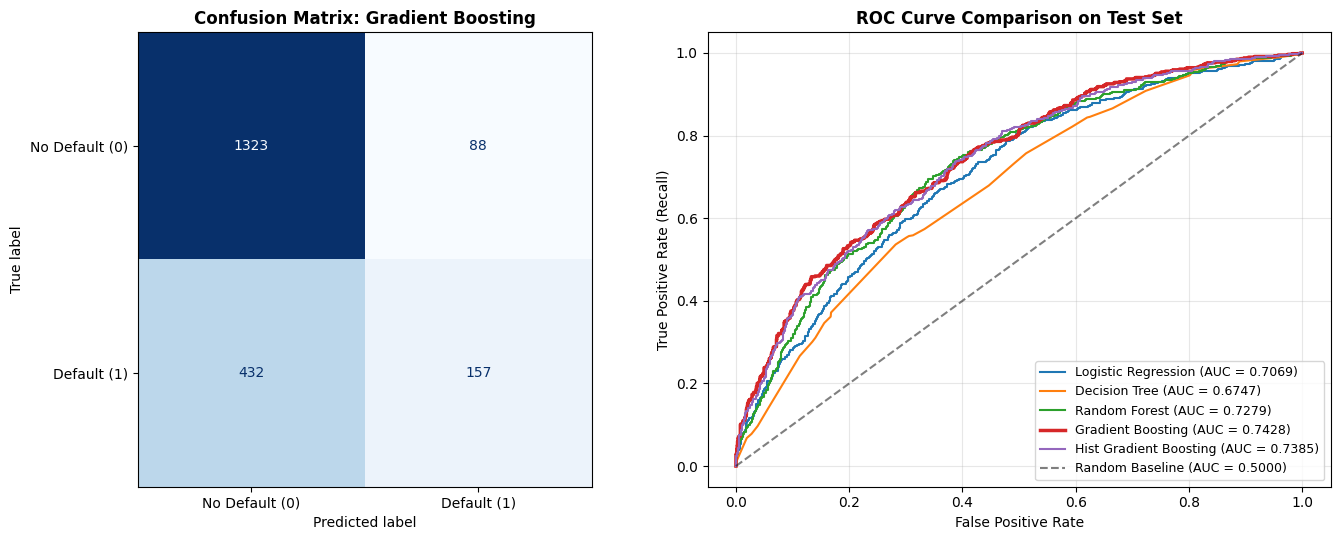

In [5]:
# ==============================================================================
# STEP 5: DETAILED PERFORMANCE EVALUATION OF THE BEST MODEL
# ==============================================================================
y_pred_best = best_pipeline.predict(X_test)
y_prob_best = best_pipeline.predict_proba(X_test)[:, 1]

print(f"=== CLASSIFICATION REPORT: {best_model_name} ===")
print(classification_report(y_test, y_pred_best, target_names=['No Default (0)', 'Default (1)']))

# Plot Confusion Matrix & ROC Curves side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Confusion Matrix for Best Model
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default (0)', 'Default (1)'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix: {best_model_name}', fontsize=12, fontweight='bold')
axes[0].grid(False)

# 2. ROC Curve Comparison Across All Models
for model_name, pipe in fitted_pipelines.items():
    probs = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_score = roc_auc_score(y_test, probs)
    lw = 2.5 if model_name == best_model_name else 1.5
    axes[1].plot(fpr, tpr, linewidth=lw, label=f"{model_name} (AUC = {auc_score:.4f})")

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Baseline (AUC = 0.5000)')
axes[1].set_title('ROC Curve Comparison on Test Set', fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== TOP 10 BUILT-IN FEATURE IMPORTANCES (IMPURITY DECREASE) ===
            Encoded_Feature  Built_in_Importance
           employment_years               0.2346
          annual_income_bdt               0.2215
      num_late_payments_12m               0.1227
   collateral_type_Property               0.0968
payment_frequency_Quarterly               0.0735
    collateral_type_Vehicle               0.0556
               credit_score               0.0389
                        age               0.0279
  payment_frequency_Monthly               0.0261
      collateral_type_Other               0.0228

=== PERMUTATION IMPORTANCE BY ORIGINAL ATTRIBUTE (TEST ROC-AUC DROP) ===
       Original_Attribute  Mean_ROC_AUC_Drop  Std_ROC_AUC_Drop
         employment_years             0.0763            0.0069
          collateral_type             0.0568            0.0054
        annual_income_bdt             0.0476            0.0047
    num_late_payments_12m             0.0274            0.0031
        

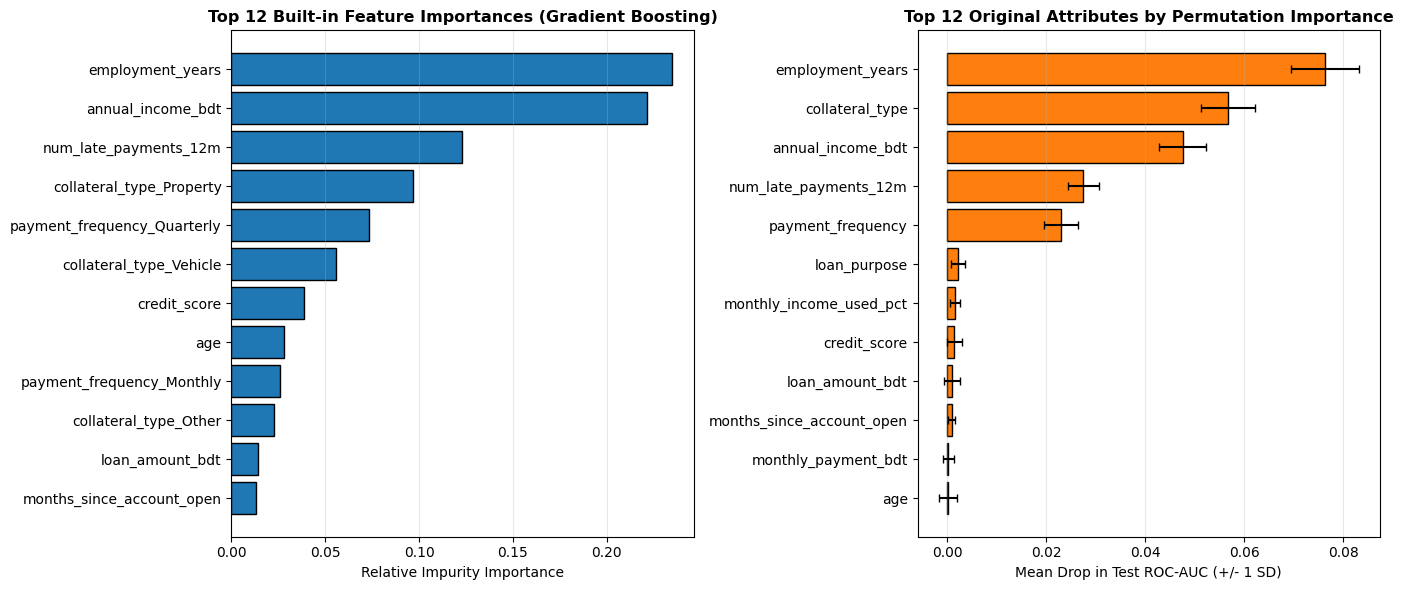

In [6]:
# ==============================================================================
# STEP 6: ATTRIBUTE IMPORTANCE ANALYSIS (BUILT-IN & PERMUTATION IMPORTANCE)
# ==============================================================================
# A. Extract Built-in Feature Importance from the Best Pipeline
ohe_mode_names = (
    best_pipeline.named_steps['preprocessor']
    .named_transformers_['cat_mode']
    .named_steps['onehot']
    .get_feature_names_out(cat_mode_features)
    .tolist()
)
ohe_const_names = (
    best_pipeline.named_steps['preprocessor']
    .named_transformers_['cat_const']
    .named_steps['onehot']
    .get_feature_names_out(cat_const_features)
    .tolist()
)
encoded_feature_names = num_features + ohe_mode_names + ohe_const_names

builtin_importance_df = pd.DataFrame({
    'Encoded_Feature': encoded_feature_names,
    'Built_in_Importance': best_pipeline.named_steps['classifier'].feature_importances_
}).sort_values(by='Built_in_Importance', ascending=False).reset_index(drop=True)

print("=== TOP 10 BUILT-IN FEATURE IMPORTANCES (IMPURITY DECREASE) ===")
print(builtin_importance_df.head(10).round(4).to_string(index=False))

# B. Compute Permutation Importance on the 17 Original Attributes (Test Set)
perm_result = permutation_importance(
    best_pipeline, X_test, y_test, n_repeats=10, random_state=42, scoring='roc_auc', n_jobs=-1
)

perm_importance_df = pd.DataFrame({
    'Original_Attribute': X.columns,
    'Mean_ROC_AUC_Drop': perm_result.importances_mean,
    'Std_ROC_AUC_Drop': perm_result.importances_std
}).sort_values(by='Mean_ROC_AUC_Drop', ascending=False).reset_index(drop=True)

print("\n=== PERMUTATION IMPORTANCE BY ORIGINAL ATTRIBUTE (TEST ROC-AUC DROP) ===")
print(perm_importance_df.round(4).to_string(index=False))

# C. Visualize Both Attribute Importance Rankings
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_builtin = builtin_importance_df.head(12).iloc[::-1]
axes[0].barh(top_builtin['Encoded_Feature'], top_builtin['Built_in_Importance'], color='#1f77b4', edgecolor='black')
axes[0].set_title(f'Top 12 Built-in Feature Importances ({best_model_name})', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Relative Impurity Importance')
axes[0].grid(True, axis='x', alpha=0.3)

top_perm = perm_importance_df.head(12).iloc[::-1]
axes[1].barh(
    top_perm['Original_Attribute'],
    top_perm['Mean_ROC_AUC_Drop'],
    xerr=top_perm['Std_ROC_AUC_Drop'],
    color='#ff7f0e',
    edgecolor='black',
    capsize=3
)
axes[1].set_title('Top 12 Original Attributes by Permutation Importance', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Mean Drop in Test ROC-AUC (+/- 1 SD)')
axes[1].grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()